<a href="https://colab.research.google.com/github/komazawa-deep-learning/komazawa-deep-learning.github.io/blob/master/2026notebooks/2026_1127pe_addition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 足し算で見る位置符号化器 (PE) の役割

0〜99 同士の足し算 (例: `12+34` → `46`) を Transformer に学習させ，PE を 3 通りに入れ替えて比べる。

| 条件 | 位置情報の入れ方 |
|---|---|
| PE なし (`none`) | なし |
| 正弦波 PE (`sinusoidal`) | 埋め込みに加算 (絶対位置) |
| RoPE (`rope`) | self-attention の Q, K を回転 (相対位置) |

このノートブックで確かめることは 2 つある。

1. **PE がないと，`12+34` と `21+43` を区別できない。** 使っている文字が同じだからである。
2. **2 桁までで学習したモデルは，3 桁の足し算を解けない。しかし，それは PE のせいではない。**

* 共通コード: `pe_transformer.py` (モデル)，`pe_tasks.py` (課題と評価)

## 1. 準備

In [ ]:
# 環境設定: Colab と ローカル Mac の両方で動く
import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules

# pe_transformer.py と pe_tasks.py を探す。
# Colab で見つからなければ GitHub から clone し，それでもなければアップロードを求める。
REPO_URL = 'https://github.com/ShinAsakawa/CDP_ja.git'   # 2 ファイルを置いたリポジトリ
NEEDED = ['pe_transformer.py', 'pe_tasks.py']

def find_dir():
    for d in ['.', 'CDP_ja']:
        if all(os.path.exists(os.path.join(d, f)) for f in NEEDED):
            return d
    return None

WORK_DIR = find_dir()
if WORK_DIR is None and IN_COLAB:
    if not os.path.exists('CDP_ja'):
        subprocess.run(['git', 'clone', '-q', REPO_URL], check=False)
    WORK_DIR = find_dir()
if WORK_DIR is None and IN_COLAB:
    from google.colab import files
    print('pe_transformer.py と pe_tasks.py をアップロードしてください')
    files.upload()
    WORK_DIR = find_dir()
assert WORK_DIR is not None, f'{NEEDED} が見つからない。このノートブックと同じフォルダに置くこと'
sys.path.insert(0, os.path.abspath(WORK_DIR))

# 日本語フォントの準備
try:
    import japanize_matplotlib
except Exception:
    try:
        import matplotlib_fontja
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'matplotlib-fontja'], check=False)
        import matplotlib_fontja

%config InlineBackend.figure_format = 'retina'
import random, time
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import pe_transformer as pt
import pe_tasks as tk

FIG_DIR = 'figures'          # 図をファイルにも保存
os.makedirs(FIG_DIR, exist_ok=True)

DEVICE = pt.get_device()
# DEVICE = torch.device('cpu')
print('Colab:', IN_COLAB, '| device:', DEVICE, '| torch:', torch.__version__)

Colab: True | device: cuda | torch: 2.14.1+cu130


In [ ]:
def show_table(header, rows, caption=''):
    """簡単な HTML 表を表示する"""
    h = ''.join(f'<th style="padding:2px 10px">{x}</th>' for x in header)
    b = ''.join('<tr>' + ''.join(f'<td style="padding:2px 10px;text-align:center">{x}</td>' for x in r) + '</tr>'
                for r in rows)
    display(HTML(f'<b>{caption}</b><table><tr>{h}</tr>{b}</table>'))

COLORS = {'none': 'tab:gray', 'sinusoidal': 'tab:blue', 'rope': 'tab:red'}
LABELS = {'none': 'PE なし', 'sinusoidal': '正弦波 PE', 'rope': 'RoPE'}

## 2. データ

* 0〜99 同士の足し算は全部で 10,000 問ある。そのうち **8,000 問で学習** し，**残り 2,000 問 (未学習の 2 桁問題)** で，規則を身につけたのか丸暗記しただけなのかを確かめる。
* さらに **3 桁を含む問題** と **4 桁を含む問題** を 500 問ずつ用意する (学習範囲の外)。

In [ ]:
all2 = tk.addition_pairs([1, 2], None)          # 0〜99 同士の全 10,000 問
rng = random.Random(0)
rng.shuffle(all2)
train, held = all2[:8000], all2[8000:]
test3 = tk.addition_pairs([1, 2, 3], 500, seed=3)       # 少なくとも一方が 3 桁
test4 = tk.addition_pairs([1, 2, 3, 4], 500, seed=4)    # 少なくとも一方が 4 桁
random.Random(1).shuffle(test3); random.Random(1).shuffle(test4)
vocab = tk.make_vocab('0123456789+')

print('学習:', len(train), '問 | 未学習の 2 桁:', len(held), '問 | 3 桁:', len(test3), '問 | 4 桁:', len(test4), '問')
print('語彙:', vocab.itos)
print('例:', train[:5], test3[:3])

学習: 8000 問 | 未学習の 2 桁: 2000 問 | 3 桁: 500 問 | 4 桁: 500 問
語彙: ['<PAD>', '<SOS>', '<EOS>', '<UNK>', '+', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
例: [('97+70', '167'), ('36+31', '67'), ('70+59', '129'), ('4+21', '25'), ('98+78', '176')] [('706+9', '715'), ('276+9', '285'), ('664+39', '703')]


## 3. 予想: PE がないと何が起きるか

* 位置符号化器 (PE) のないエンコーダは，入力を **文字の集まり (多重集合)** としてしか見られない
<!-- (`pe_2x2_shuffle.ipynb` の並べ替えテストを参照)。 -->
*  すると，同じ文字からなる問題は **すべて同じ問題に見える**。たとえば `12+34` と同じ文字 {1, 2, 3, 4, +} からなる問題を全部挙げてみる。

In [ ]:
from collections import defaultdict
groups = defaultdict(list)
for q, a in all2:
    groups[tuple(sorted(q))].append((q, a))

same = sorted(groups[tuple(sorted('12+34'))])
print(f'{{1,2,3,4,+}} からなる問題: {len(same)} 問, 答えは {len(set(a for _, a in same))} 種類')
for q, a in same:
    print(f'  {q:>6s} = {a}')

ub = tk.bag_upper_bound(all2)
print(f'\n順序を見ないモデルの正解率の理論上限: {ub:.3f}')
print('(各グループで最も多い答えを常に出したときの正解率。これ以上は原理的に不可能)')

{1,2,3,4,+} からなる問題: 24 問, 答えは 5 種類
   12+34 = 46
   12+43 = 55
   13+24 = 37
   13+42 = 55
   14+23 = 37
   14+32 = 46
   21+34 = 55
   21+43 = 64
   23+14 = 37
   23+41 = 64
   24+13 = 37
   24+31 = 55
   31+24 = 55
   31+42 = 73
   32+14 = 46
   32+41 = 73
   34+12 = 46
   34+21 = 55
   41+23 = 64
   41+32 = 73
   42+13 = 55
   42+31 = 73
   43+12 = 55
   43+21 = 64

順序を見ないモデルの正解率の理論上限: 0.361
(各グループで最も多い答えを常に出したときの正解率。これ以上は原理的に不可能)


## 4. 学習

3 条件 × 3 シード。CPU で 1 条件あたり 1 分前後，合計 10 分程度かかる (Colab の GPU ならもっと速い)。
時間を短くしたいときは `SEEDS = [0]` にする。

In [ ]:
cfg = pt.Config(model_dim=64, num_heads=4, num_layers=2, ff_dim=128,
                epochs=30, batch_size=256, lr=2e-3, lr_schedule='cosine', eval_every=30)
CONDITIONS = ['none', 'sinusoidal', 'rope']
SEEDS = [0, 1, 2]

models, times = {}, {}
for pe in CONDITIONS:
    for seed in SEEDS:
        cfg.seed = seed
        m, h = tk.train_task(cfg, train, vocab, pe, pe, device=DEVICE)
        models[(pe, seed)], times[(pe, seed)] = m, h['time']
        print(f'{LABELS[pe]:>8s} seed={seed}: {h["time"]:.0f} 秒')
print('パラメータ数:', pt.count_params(models[('rope', 0)]))

   PE なし seed=0: 17 秒
   PE なし seed=1: 16 秒
   PE なし seed=2: 16 秒
  正弦波 PE seed=0: 17 秒
  正弦波 PE seed=1: 16 秒
  正弦波 PE seed=2: 16 秒
    RoPE seed=0: 21 秒
    RoPE seed=1: 20 秒
    RoPE seed=2: 21 秒
パラメータ数: 170319


## 5. 2 桁の範囲での正解率

In [6]:
acc = {}   # (条件, シード, データ名) -> 評価結果
for (pe, seed), m in models.items():
    for name, ps in [('学習', train), ('未学習2桁', held), ('3桁', test3), ('4桁', test4)]:
        acc[(pe, seed, name)] = tk.accuracy(m, ps, vocab, DEVICE)

def mean_sd(pe, name, key='exact'):
    v = [acc[(pe, s, name)][key] for s in SEEDS]
    return f'{np.mean(v):.3f} ± {np.std(v):.3f}'

show_table(['条件', '学習した問題', '未学習の 2 桁問題', '理論上限 (順序を見ない場合)'],
           [[LABELS[pe], mean_sd(pe, '学習'), mean_sd(pe, '未学習2桁'), f'{ub:.3f}' if pe == 'none' else '—']
            for pe in CONDITIONS],
           '完全一致率 (3 シードの平均 ± 標準偏差)')

条件,学習した問題,未学習の 2 桁問題,理論上限 (順序を見ない場合)
PE なし,0.362 ± 0.002,0.270 ± 0.004,0.361
正弦波 PE,1.000 ± 0.000,0.996 ± 0.002,—
RoPE,1.000 ± 0.000,0.997 ± 0.002,—


**読み方**

* 正弦波 PE と RoPE は，**未学習の 2 桁問題** でもほぼ全問正解する。丸暗記ではなく，2 桁の足し算の規則を身につけている。
* PE なしは，学習した問題でも正解率が **理論上限付近** で止まる。失敗の原因は「文字の順序が見えないこと」でほぼすべて説明できる。

## 6. 実演: `12+34` と `21+43`

In [7]:
probes = ['12+34', '21+43', '34+12', '43+21', '13+24', '31+42', '99+1', '1+99', '5+7', '50+70']
P = [(q, str(eval(q))) for q in probes]
outs = {pe: tk.accuracy(models[(pe, 0)], P, vocab, DEVICE)['preds'] for pe in CONDITIONS}

def mark(p, a):
    return p if p == a else f'<b style="color:red">{p}</b>'

show_table(['問題', '正解'] + [LABELS[pe] for pe in CONDITIONS],
           [[q, a] + [mark(outs[pe][i], a) for pe in CONDITIONS] for i, (q, a) in enumerate(P)],
           'シード 0 のモデルの答え (赤字は誤り)')

問題,正解,PE なし,正弦波 PE,RoPE
12+34,46,55,46,46
21+43,64,55,64,64
34+12,46,55,46,46
43+21,64,55,64,64
13+24,37,55,37,37
31+42,73,55,73,73
99+1,100,100,100,100
1+99,100,100,100,100
5+7,12,12,12,12
50+70,120,120,120,120


**考えてみよう**: PE なしのモデルは `12+34`，`21+43`，`34+12`，`43+21` に何と答えたか。なぜ 4 問とも同じ答えになるのか。
3 節の一覧で，{1, 2, 3, 4, +} からなる 24 問の答えのうち **最も多いもの** は何だったか。モデルの答えと比べよ。
一方，`99+1` と `1+99` はなぜ両方とも正解できるのか。

## 7. 3 桁・4 桁の問題

次に，学習範囲の外 (3 桁・4 桁) を見る。

In [8]:
show_table(['条件', '未学習の 2 桁', '3 桁を含む', '4 桁を含む'],
           [[LABELS[pe], mean_sd(pe, '未学習2桁'), mean_sd(pe, '3桁'), mean_sd(pe, '4桁')] for pe in CONDITIONS],
           '完全一致率 (3 シードの平均 ± 標準偏差)')

# 生成例
rows = []
for q, a in test3[:8] + [('100+23', '123'), ('200+300', '500'), ('0+210', '210')]:
    preds = [tk.accuracy(models[(pe, 0)], [(q, a)], vocab, DEVICE)['preds'][0] for pe in CONDITIONS]
    rows.append([q, a] + [mark(p, a) for p in preds])
show_table(['問題', '正解'] + [LABELS[pe] for pe in CONDITIONS], rows, '3 桁を含む問題の答え (シード 0)')

条件,未学習の 2 桁,3 桁を含む,4 桁を含む
PE なし,0.270 ± 0.004,0.000 ± 0.000,0.000 ± 0.000
正弦波 PE,0.996 ± 0.002,0.000 ± 0.000,0.000 ± 0.000
RoPE,0.997 ± 0.002,0.000 ± 0.000,0.000 ± 0.000


問題,正解,PE なし,正弦波 PE,RoPE
706+9,715,157,139,149
276+9,285,105,96,106
664+39,703,159,111,133
718+93,811,168,168,142
261+1,262,37,37,82
764+7,771,141,123,142
665+27,692,139,129,92
7+956,963,135,114,153
100+23,123,50,83,33
200+300,500,10,73,90


### 7.1 どこまで合っているのか: 桁ごとの正解率

答えを **下の桁 (右端) から揃えて**，一の位・十の位・百の位ごとに正解率を見る。でたらめに答えた場合の正解率は約 10% である。

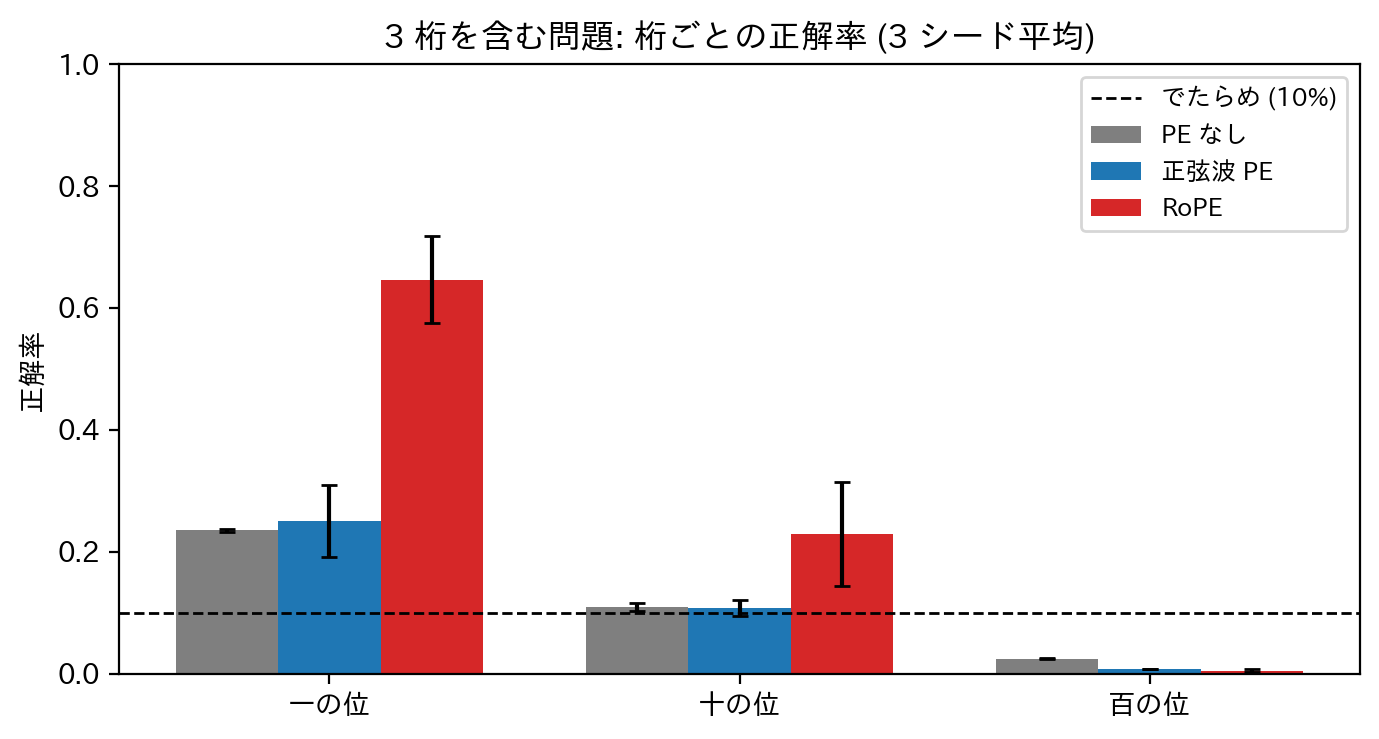

In [9]:
pos_names = ['一の位', '十の位', '百の位']
fig, ax = plt.subplots(figsize=(7, 3.8))
w = 0.25
for j, pe in enumerate(CONDITIONS):
    vals = np.array([[tk.digit_accuracy_from_right(test3, acc[(pe, s, '3桁')]['preds'], 3).get(k, np.nan)
                      for k in range(3)] for s in SEEDS])
    ax.bar(np.arange(3) + (j - 1) * w, vals.mean(0), w, yerr=vals.std(0), capsize=3,
           color=COLORS[pe], label=LABELS[pe])
ax.axhline(0.1, color='k', ls='--', lw=1, label='でたらめ (10%)')
ax.set_xticks(range(3)); ax.set_xticklabels(pos_names); ax.set_ylim(0, 1)
ax.set_ylabel('正解率'); ax.set_title('3 桁を含む問題: 桁ごとの正解率 (3 シード平均)')
ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/add_digit_accuracy.png', dpi=200); plt.show()

### 7.2 答えの桁数

4 桁を含む問題 (正解は 4 桁または 5 桁) に，モデルは何桁で答えたか。

In [10]:
from collections import Counter
for pe in CONDITIONS:
    c = Counter()
    for s in SEEDS:
        for (q, a), p in zip(test4, acc[(pe, s, '4桁')]['preds']):
            c[(len(a), len(p))] += 1
    print(LABELS[pe], ' | '.join(f'正解 {g} 桁 → 出力 {o} 桁: {n} 件' for (g, o), n in sorted(c.items())))
print('\n学習データの答えは最長 3 桁 (99+99=198)。')

PE なし 正解 4 桁 → 出力 2 桁: 107 件 | 正解 4 桁 → 出力 3 桁: 1279 件 | 正解 4 桁 → 出力 4 桁: 3 件 | 正解 5 桁 → 出力 2 桁: 21 件 | 正解 5 桁 → 出力 3 桁: 86 件 | 正解 5 桁 → 出力 4 桁: 4 件
正弦波 PE 正解 4 桁 → 出力 2 桁: 500 件 | 正解 4 桁 → 出力 3 桁: 889 件 | 正解 5 桁 → 出力 2 桁: 21 件 | 正解 5 桁 → 出力 3 桁: 90 件
RoPE 正解 4 桁 → 出力 2 桁: 542 件 | 正解 4 桁 → 出力 3 桁: 847 件 | 正解 5 桁 → 出力 2 桁: 28 件 | 正解 5 桁 → 出力 3 桁: 83 件

学習データの答えは最長 3 桁 (99+99=198)。


## 8. なぜ 3 桁は解けないのか

* どの PE でも 3 桁の **完全一致率は 0** である。正弦波 PE と RoPE は，学習で見た最長の 3 桁を超える答えを一度も出さない
  (PE なしはときどき 4 桁を出すが，でたらめである)。
* 誤答 (`100+23` → 2 桁の数など) は，3 桁の数を「3 桁の数」として読めていないことを示す。
* ただし **桁ごとに見ると差がある** (7.1 節)。RoPE は一の位・十の位を偶然 (10%) よりかなり高い割合で正解する。正弦波 PE はそうでもない。
  **百の位は，どの PE でもほぼ 0** である。

ここで，学習データに何が含まれていなかったかを考える。

* 学習データでは，**入力の数字は必ず「一の位」か「十の位」** だった。入力に **百の位の数字が現れたことは一度もない**。
* **一の位・十の位** を計算するのに必要なのは，「`+` や末尾から数えて何番目の数字か」という **相対的な位置** だけで，これは 3 桁の問題でも学習時と同じである。
  相対位置を表す RoPE がここで有利になるのは，逆唱で末尾から正しく始められたのと同じ理由である。
* **百の位** を計算するには，「見たことのない位置」を扱うだけでなく，**「百の位」という，学習データにまったく含まれていない概念** が必要になる。
  どんな PE を使っても，データに一度も現れないことは学べない。PE が変えられるのは **位置の表し方** であって，学ぶ内容そのものではない。

つまり **「3 桁が解けない」ことの主な原因は PE ではなく，学習データにない概念である。PE の違いは，位置の外挿だけで済む部分 (下の桁) に表れる。**

逆唱 (`pe_reversal.ipynb`) と比べるとよくわかる。逆唱では，入力が 6 文字になっても「後ろから数えて対応する位置の文字を写す」という操作は学習時と同じである。必要なのは **位置の外挿だけ** なので，PE の違いが結果にはっきり表れる。

| | 足し算 2 桁 → 3 桁 | 逆唱 5 文字 → 6 文字 |
|---|---|---|
| 未知の位置 | あり | あり |
| 未知の概念 (百の位，4 桁の答え) | **あり** | なし |
| PE の比較に使えるか | 完全一致率では使えない (原因が混ざる)。桁ごとに分ければ一部使える | 使える |

## 9. 考えてみよう

1. PE なしのモデルが `99+1` と `1+99` の両方に正解できたのはなぜか。正解率が理論上限を超えられないのはなぜか。
2. 「2 桁で学習して 3 桁を解かせる」実験の完全一致率で，PE の良し悪しを判定してよいか。桁ごとの正解率を見ると何がわかるか。
3. 3 桁の問題を解かせたいなら，学習データをどう変えればよいか。そのとき，その実験は「長さの外挿」を測っていると言えるか。
4. 人間の子どもは，2 桁の筆算を習ったあと 3 桁の筆算をすぐにできるようになる。モデルと何が違うのか。